
   FUZZY ROBOTIC ARM CONTROLLER
1. Calculate Motor Torque
2. Error Membership Functions
3. Change in Error Membership Functions
4. Torque Membership Functions
5. Display Fuzzy Control Rules
6. Simulate Robotic Arm Movement
7. Exit

Enter your choice (1-7): 1
Enter Error (-10 to 10): 40
Enter Change in Error (-5 to 5): 5
Error must be between -10 and 10.

   FUZZY ROBOTIC ARM CONTROLLER
1. Calculate Motor Torque
2. Error Membership Functions
3. Change in Error Membership Functions
4. Torque Membership Functions
5. Display Fuzzy Control Rules
6. Simulate Robotic Arm Movement
7. Exit

Enter your choice (1-7): 1
Enter Error (-10 to 10): 9
Enter Change in Error (-5 to 5): 3

========== RESULTS ==========
Input Error: 9.0
Change in Error: 3.0
Calculated Motor Torque: 6.29
Motor Direction: Positive


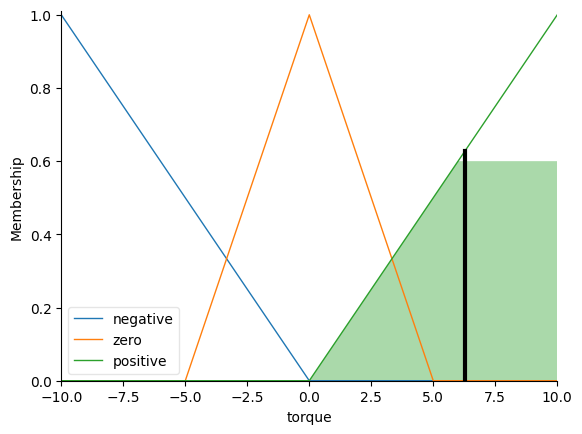


   FUZZY ROBOTIC ARM CONTROLLER
1. Calculate Motor Torque
2. Error Membership Functions
3. Change in Error Membership Functions
4. Torque Membership Functions
5. Display Fuzzy Control Rules
6. Simulate Robotic Arm Movement
7. Exit

Enter your choice (1-7): 2


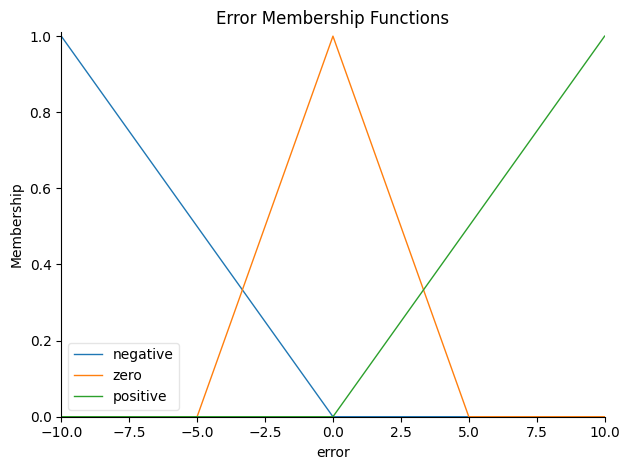


   FUZZY ROBOTIC ARM CONTROLLER
1. Calculate Motor Torque
2. Error Membership Functions
3. Change in Error Membership Functions
4. Torque Membership Functions
5. Display Fuzzy Control Rules
6. Simulate Robotic Arm Movement
7. Exit

Enter your choice (1-7): 3


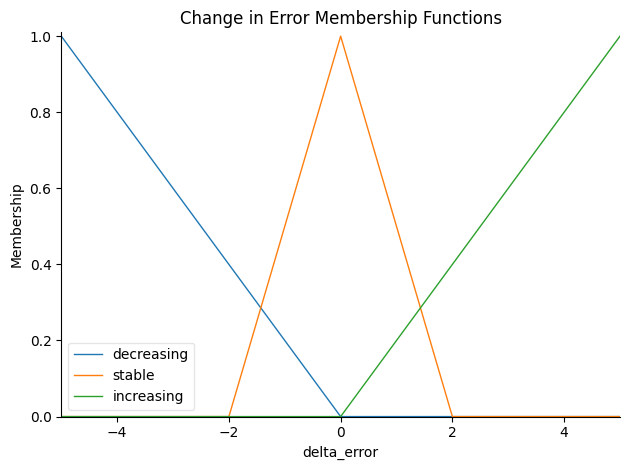


   FUZZY ROBOTIC ARM CONTROLLER
1. Calculate Motor Torque
2. Error Membership Functions
3. Change in Error Membership Functions
4. Torque Membership Functions
5. Display Fuzzy Control Rules
6. Simulate Robotic Arm Movement
7. Exit

Enter your choice (1-7): 4


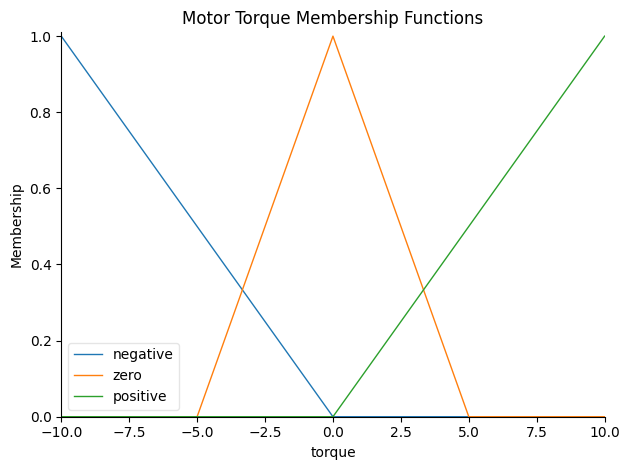


   FUZZY ROBOTIC ARM CONTROLLER
1. Calculate Motor Torque
2. Error Membership Functions
3. Change in Error Membership Functions
4. Torque Membership Functions
5. Display Fuzzy Control Rules
6. Simulate Robotic Arm Movement
7. Exit

Enter your choice (1-7): 5

========== FUZZY CONTROL RULES ==========
1. IF Error is Negative AND Change is Decreasing THEN Torque is Negative
2. IF Error is Negative AND Change is Stable THEN Torque is Negative
3. IF Error is Negative AND Change is Increasing THEN Torque is Negative
4. IF Error is Zero AND Change is Decreasing THEN Torque is Negative
5. IF Error is Zero AND Change is Stable THEN Torque is Zero
6. IF Error is Zero AND Change is Increasing THEN Torque is Positive
7. IF Error is Positive AND Change is Decreasing THEN Torque is Positive
8. IF Error is Positive AND Change is Stable THEN Torque is Positive
9. IF Error is Positive AND Change is Increasing THEN Torque is Positive

   FUZZY ROBOTIC ARM CONTROLLER
1. Calculate Motor Torque
2. Error 

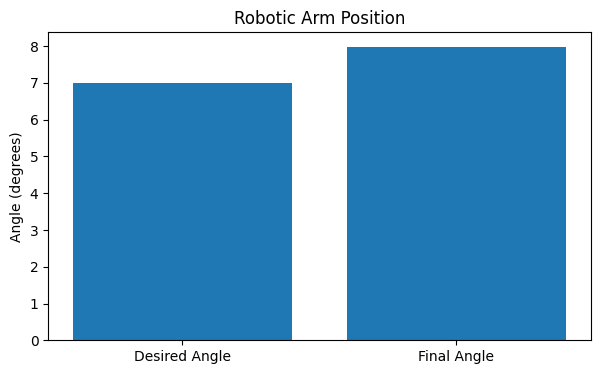


   FUZZY ROBOTIC ARM CONTROLLER
1. Calculate Motor Torque
2. Error Membership Functions
3. Change in Error Membership Functions
4. Torque Membership Functions
5. Display Fuzzy Control Rules
6. Simulate Robotic Arm Movement
7. Exit

Enter your choice (1-7): 7

Exiting Robotic Arm Controller. Thank you!


In [2]:
 !pip install scikit-fuzzy
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl


# ==========================================
# 1. DEFINE FUZZY VARIABLES
# ==========================================

error = ctrl.Antecedent(
    np.arange(-10, 11, 1), 'error'
)

delta_error = ctrl.Antecedent(
    np.arange(-5, 6, 1), 'delta_error'
)

torque = ctrl.Consequent(
    np.arange(-10, 11, 1), 'torque'
)


# ==========================================
# 2. DEFINE MEMBERSHIP FUNCTIONS
# ==========================================

# Error Membership Functions
error['negative'] = fuzz.trimf(
    error.universe, [-10, -10, 0]
)

error['zero'] = fuzz.trimf(
    error.universe, [-5, 0, 5]
)

error['positive'] = fuzz.trimf(
    error.universe, [0, 10, 10]
)


# Change in Error Membership Functions
delta_error['decreasing'] = fuzz.trimf(
    delta_error.universe, [-5, -5, 0]
)

delta_error['stable'] = fuzz.trimf(
    delta_error.universe, [-2, 0, 2]
)

delta_error['increasing'] = fuzz.trimf(
    delta_error.universe, [0, 5, 5]
)


# Torque Membership Functions
torque['negative'] = fuzz.trimf(
    torque.universe, [-10, -10, 0]
)

torque['zero'] = fuzz.trimf(
    torque.universe, [-5, 0, 5]
)

torque['positive'] = fuzz.trimf(
    torque.universe, [0, 10, 10]
)


# ==========================================
# 3. DEFINE FUZZY RULES
# ==========================================

# Negative error rules
rule1 = ctrl.Rule(
    error['negative'] & delta_error['decreasing'],
    torque['negative']
)

rule2 = ctrl.Rule(
    error['negative'] & delta_error['stable'],
    torque['negative']
)

rule3 = ctrl.Rule(
    error['negative'] & delta_error['increasing'],
    torque['negative']
)


# Zero error rules
rule4 = ctrl.Rule(
    error['zero'] & delta_error['decreasing'],
    torque['negative']
)

rule5 = ctrl.Rule(
    error['zero'] & delta_error['stable'],
    torque['zero']
)

rule6 = ctrl.Rule(
    error['zero'] & delta_error['increasing'],
    torque['positive']
)


# Positive error rules
rule7 = ctrl.Rule(
    error['positive'] & delta_error['decreasing'],
    torque['positive']
)

rule8 = ctrl.Rule(
    error['positive'] & delta_error['stable'],
    torque['positive']
)

rule9 = ctrl.Rule(
    error['positive'] & delta_error['increasing'],
    torque['positive']
)


# ==========================================
# 4. BUILD FUZZY CONTROL SYSTEM
# ==========================================

torque_ctrl = ctrl.ControlSystem([
    rule1, rule2, rule3,
    rule4, rule5, rule6,
    rule7, rule8, rule9
])


# ==========================================
# 5. FUNCTION TO CALCULATE TORQUE
# ==========================================

def calculate_torque(error_value, delta_value):

    simulation = ctrl.ControlSystemSimulation(
        torque_ctrl
    )

    simulation.input['error'] = error_value
    simulation.input['delta_error'] = delta_value

    simulation.compute()

    return simulation.output['torque'], simulation


# ==========================================
# 6. DISPLAY FUZZY RULES
# ==========================================

def display_rules():

    print("\n========== FUZZY CONTROL RULES ==========")

    rules = [
        "1. IF Error is Negative AND Change is Decreasing THEN Torque is Negative",
        "2. IF Error is Negative AND Change is Stable THEN Torque is Negative",
        "3. IF Error is Negative AND Change is Increasing THEN Torque is Negative",
        "4. IF Error is Zero AND Change is Decreasing THEN Torque is Negative",
        "5. IF Error is Zero AND Change is Stable THEN Torque is Zero",
        "6. IF Error is Zero AND Change is Increasing THEN Torque is Positive",
        "7. IF Error is Positive AND Change is Decreasing THEN Torque is Positive",
        "8. IF Error is Positive AND Change is Stable THEN Torque is Positive",
        "9. IF Error is Positive AND Change is Increasing THEN Torque is Positive"
    ]

    for rule in rules:
        print(rule)


# ==========================================
# 7. PLOT MEMBERSHIP FUNCTIONS
# ==========================================

def plot_membership(variable, title):

    variable.view()

    plt.title(title)
    plt.tight_layout()
    plt.show()


# ==========================================
# 8. SIMULATE ROBOTIC ARM MOVEMENT
# ==========================================

def simulate_robotic_arm():

    print("\n========== ROBOTIC ARM SIMULATION ==========")

    target_angle = float(
        input("Enter desired arm angle (0-90 degrees): ")
    )

    current_angle = float(
        input("Enter current arm angle (0-90 degrees): ")
    )

    if not (0 <= target_angle <= 90 and
            0 <= current_angle <= 90):

        print("Angles must be between 0 and 90 degrees.")
        return

    velocity = 0.0
    previous_error = None

    dt = 0.1

    print("\nStarting robotic arm simulation...\n")
    print("Step | Arm Angle | Error | Torque")

    for step in range(1, 151):

        # Calculate normalized error
        error_value = np.clip(
            (target_angle - current_angle) / 9,
            -10, 10
        )

        if previous_error is None:
            delta_value = 0.0
        else:
            delta_value = np.clip(
                error_value - previous_error,
                -5, 5
            )

        previous_error = error_value

        # Calculate fuzzy torque
        torque_value, _ = calculate_torque(
            error_value, delta_value
        )

        # Simplified arm dynamics
        acceleration = (
            3.0 * torque_value - 1.2 * velocity
        )

        velocity = velocity + acceleration * dt

        velocity = np.clip(velocity, -30, 30)

        current_angle = (
            current_angle + velocity * dt
        )

        current_angle = np.clip(
            current_angle, 0, 90
        )

        if step % 10 == 0:
            print(
                f"{step:4d} | {current_angle:9.2f} | "
                f"{target_angle-current_angle:6.2f} | "
                f"{torque_value:6.2f}"
            )

        if (abs(target_angle - current_angle) < 1
                and abs(velocity) < 1):

            print("\nTarget angle reached!")
            break

    print("\nFinal Arm Angle:",
          round(current_angle, 2), "degrees")

    print("Desired Arm Angle:",
          target_angle, "degrees")

    # Plot arm movement
    plt.figure(figsize=(7, 4))

    plt.bar(
        ["Desired Angle", "Final Angle"],
        [target_angle, current_angle]
    )

    plt.ylabel("Angle (degrees)")
    plt.title("Robotic Arm Position")
    plt.show()


# ==========================================
# 9. MAIN MENU
# ==========================================

while True:

    print("\n====================================")
    print("   FUZZY ROBOTIC ARM CONTROLLER")
    print("====================================")

    print("1. Calculate Motor Torque")
    print("2. Error Membership Functions")
    print("3. Change in Error Membership Functions")
    print("4. Torque Membership Functions")
    print("5. Display Fuzzy Control Rules")
    print("6. Simulate Robotic Arm Movement")
    print("7. Exit")

    choice = input("\nEnter your choice (1-7): ")

    if choice == "1":

        try:
            e = float(input("Enter Error (-10 to 10): "))
            de = float(input("Enter Change in Error (-5 to 5): "))

            if not (-10 <= e <= 10):
                print("Error must be between -10 and 10.")

            elif not (-5 <= de <= 5):
                print("Change in Error must be between -5 and 5.")

            else:
                output, simulation = calculate_torque(e, de)

                print("\n========== RESULTS ==========")
                print("Input Error:", e)
                print("Change in Error:", de)
                print("Calculated Motor Torque:",
                      round(output, 2))

                if output > 1:
                    print("Motor Direction: Positive")
                elif output < -1:
                    print("Motor Direction: Negative")
                else:
                    print("Motor Direction: Nearly Zero")

                torque.view(sim=simulation)
                plt.show()

        except ValueError:
            print("Please enter valid numerical values.")

    elif choice == "2":

        plot_membership(
            error,
            "Error Membership Functions"
        )

    elif choice == "3":

        plot_membership(
            delta_error,
            "Change in Error Membership Functions"
        )

    elif choice == "4":

        plot_membership(
            torque,
            "Motor Torque Membership Functions"
        )

    elif choice == "5":

        display_rules()

    elif choice == "6":

        try:
            simulate_robotic_arm()

        except ValueError:
            print("Please enter valid numerical values.")

    elif choice == "7":

        print("\nExiting Robotic Arm Controller. Thank you!")
        break

    else:

        print("\nInvalid choice! Please select from 1 to 7.")
